<h1 align = "Center">
Lotus Group Customer Behavior Analysis

<h2 align = "Center">
Feature Engineering, Target Construction & Machine Learning
</h2>
</h1>

## Modelling Objectives

This notebook addresses specific objectives 3–6 of the project charter:

| Objective | Section of this notebook |
|---|---|
| 3. Engineer customer-level features without using future information | Observation-Date Framework; Historical Features and Prediction Targets |
| 4. Classification: will a customer make a qualifying purchase in the next 90 days? | Classification |
| 5. Regression: how much will a customer spend in the next 90 days? | Regression |
| 6. Evaluate against baselines and interpret in business terms | Chronological Split and Baselines through Conclusions |

**1. Classification target – `will_purchase`**
- 1 = the customer makes at least one qualifying (Completed) purchase in the 90 days after the observation date.
- 0 = no qualifying purchase.

**2. Regression target – `future_spending`**
- Total revenue (EGP) from the customer's qualifying purchases in the same 90-day window. Customers who do not purchase receive 0.

### Modelling approach

Every prediction must use only information available at its observation date.

For example, when predicting behaviour as at 31 December 2023:
- Historical features use orders placed **on or before** 31 December 2023.
- Orders placed **after** that date are used only to construct the targets.

We repeat this at quarterly observation dates, which gives us many customer-observation records and lets us validate chronologically: train on earlier observations, test on later ones.

We retain registered customers even if they have never purchased. Identifying potential first-time buyers is also commercially valuable.

### Notebook structure

- Setup and data loading
- Business rules for qualifying purchases
- Observation-date framework
- Historical features and prediction targets
- Modelling dataset preparation
- Chronological split and baselines
- Classification models
- Regression models
- Diagnosing the results: does purchase history carry predictive signal?
- Conclusions, business implications and limitations

# Setup and Data Loading

We set a few display options and project-wide constants here. Libraries are imported in the cell where they are first needed, so each step shows exactly what it depends on.

In [1]:
import warnings
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)

RANDOM_STATE = 42
HORIZON_DAYS = 90          # length of the prediction window
TRAIN_END = "2023-12-31"   # last observation date used for training

### Loading the cleaned tables

We load the processed outputs from `02_data_cleaning.ipynb`. The path is relative to the `03_Notebooks` folder.

> The folder is `01_Data`. Windows ignores letter case in paths, but macOS/Linux and GitHub-hosted runners do not, so we match the repository exactly.

In [2]:
from pathlib import Path

data_path = Path("../01_Data/processed")

def load_csv(filename, date_columns=None):
    """Load a processed table, drop the saved CSV index and parse dates."""
    df = pd.read_csv(data_path / filename)
    df = df.drop(columns="Unnamed: 0", errors="ignore")
    for column in date_columns or []:
        df[column] = pd.to_datetime(df[column], errors="coerce")
    return df

customers = load_csv(
    "customers_clean.csv",
    date_columns=["birth_date", "registration_date"]
)
orders = load_csv("orders_clean.csv", date_columns=["order_date"])

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order date range:", orders["order_date"].min().date(),
      "to", orders["order_date"].max().date())
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())
print("Unparsed order dates:", orders["order_date"].isna().sum())

Customers: (3000, 10)
Orders: (12000, 10)
Order date range: 2022-01-01 to 2024-12-31
Duplicate customer IDs: 0
Unparsed order dates: 0

Parsing dates once, at load time, avoids the problem of comparing text dates with datetime values later in the notebook.

# Business Rules for Qualifying Purchases

From the data quality log we agreed the following treatment:

| Order status | Treatment |
|---|---|
| Completed | Qualifying purchase; revenue counts |
| Cancelled | Not a qualifying purchase; excluded |
| Returned | Not a qualifying purchase; excluded |

Because no Completed order has an associated return record, *completed revenue* is already *net of refunds*. We therefore don't need a separate refund deduction.

### Orders placed before customer registration

Some orders are dated before the customer's registration date. We treat these as inconsistent records and **exclude them from both features and targets**, so a single, consistent order history is used throughout the notebook.

In [3]:
orders = orders.merge(
    customers[["customer_id", "registration_date"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

pre_registration = orders["order_date"] < orders["registration_date"]

print("Orders before registration:", pre_registration.sum(),
      f"({pre_registration.mean():.1%} of all orders)")
print("Customers affected:",
      orders.loc[pre_registration, "customer_id"].nunique())

# One consistent order history for the whole notebook
valid_orders = (
    orders.loc[~pre_registration]
    .drop(columns="registration_date")
    .reset_index(drop=True)
)

completed_orders = valid_orders[
    valid_orders["order_status"] == "Completed"
].copy()

print("\nValid orders retained:", len(valid_orders))
print(valid_orders["order_status"].value_counts())

Orders before registration: 2034 (17.0% of all orders)
Customers affected: 993

Valid orders retained: 9966
order_status
Completed    8654
Returned      889
Cancelled     423
Name: count, dtype: int64

Roughly one in six orders predates the customer's registration. That is a large share, and it's characteristic of synthetic data where orders and registration dates were generated independently. We record it as a limitation in the conclusions.

# Observation-Date Framework

The data covers 1 January 2022 to 31 December 2024. We use quarter-end observation dates:

- **First:** 31 March 2022. This gives three months of history before the first observation.
- **Last:** 30 September 2024. Its 90-day window ends on 29 December 2024, which is still inside the data. A later date would have an incomplete target window.

| Transaction category | Date condition |
|---|---|
| Historical (features) | `order_date <= snapshot_date` |
| Future (targets) | `snapshot_date < order_date <= snapshot_date + 90 days` |

In [4]:
snapshots = pd.DataFrame({
    "snapshot_date": pd.date_range("2022-03-31", "2024-09-30", freq="QE")
})
snapshots["target_end_date"] = (
    snapshots["snapshot_date"] + pd.Timedelta(days=HORIZON_DAYS)
)

print("Number of observation dates:", len(snapshots))
snapshots

Number of observation dates: 11

,snapshot_date,target_end_date
0,2022-03-31,2022-06-29
1,2022-06-30,2022-09-28
2,2022-09-30,2022-12-29
3,2022-12-31,2023-03-31
4,2023-03-31,2023-06-29
5,2023-06-30,2023-09-28
6,2023-09-30,2023-12-29
7,2023-12-31,2024-03-30
8,2024-03-31,2024-06-29
9,2024-06-30,2024-09-28


### Customer-snapshot grid

We create one record per customer per observation date, keeping only customers who were registered by that date.

In [5]:
customer_snapshots = (
    customers.merge(snapshots, how="cross")
    .query("registration_date <= snapshot_date")
    .sort_values(["snapshot_date", "customer_id"])
    .reset_index(drop=True)
)

print("Customer-observation records:", len(customer_snapshots))
print("Unique customers:", customer_snapshots["customer_id"].nunique())
print("Observation dates:", customer_snapshots["snapshot_date"].nunique())

customer_snapshots.groupby("snapshot_date").size().rename("eligible_customers")

Customer-observation records: 27548
Unique customers: 3000
Observation dates: 11

snapshot_date
2022-03-31    1671
2022-06-30    1855
2022-09-30    2023
2022-12-31    2199
2023-03-31    2399
2023-06-30    2603
2023-09-30    2798
2023-12-31    3000
2024-03-31    3000
2024-06-30    3000
2024-09-30    3000

The number of eligible customers grows over time as new customers register. The latest observation dates include all 3,000 customers.

# Historical Features and Prediction Targets

## Historical features

All features use only orders dated on or before the observation date.

| Group | Feature | Meaning |
|---|---|---|
| RFM | `recency_days` | Days since the last completed purchase (missing if none) |
| | `total_orders` | Completed orders to date |
| | `total_spending` | Completed revenue to date |
| | `average_order_value` | Mean completed order value |
| Recent activity | `orders_last_90/180/365_days` | Completed orders in the trailing window |
| | `spending_last_90/180/365_days` | Completed revenue in the trailing window |
| Purchase pattern | `active_span_days` | Days between first and last completed purchase |
| | `distinct_stores` | Number of stores the customer has bought from |
| Service experience | `returned_orders`, `cancelled_orders` | Count of returned / cancelled orders to date |

Cumulative totals alone can't distinguish a customer who spent heavily two years ago from one who is active now. The trailing-window features capture *recent* behaviour, and the returned/cancelled counts capture service experience.

In [6]:
def calculate_customer_features(snapshot_date):
    """Customer-level features using only orders on or before snapshot_date."""

    history = valid_orders[valid_orders["order_date"] <= snapshot_date]
    completed = history[history["order_status"] == "Completed"]

    features = completed.groupby("customer_id").agg(
        first_purchase=("order_date", "min"),
        last_purchase=("order_date", "max"),
        total_orders=("order_id", "nunique"),
        total_spending=("total_revenue", "sum"),
        average_order_value=("total_revenue", "mean"),
        distinct_stores=("store_id", "nunique"),
    )

    features["recency_days"] = (snapshot_date - features["last_purchase"]).dt.days
    features["active_span_days"] = (
        features["last_purchase"] - features["first_purchase"]
    ).dt.days

    # Trailing-window activity
    for days in (90, 180, 365):
        window = completed[
            completed["order_date"] > snapshot_date - pd.Timedelta(days=days)
        ].groupby("customer_id")
        features[f"orders_last_{days}_days"] = window["order_id"].nunique()
        features[f"spending_last_{days}_days"] = window["total_revenue"].sum()

    # Non-qualifying order history (all statuses use the same date rule)
    for status, column in [("Returned", "returned_orders"),
                           ("Cancelled", "cancelled_orders")]:
        counts = (
            history[history["order_status"] == status]
            .groupby("customer_id").size().rename(column)
        )
        features = features.join(counts, how="outer")

    return (
        features.drop(columns=["first_purchase", "last_purchase"])
        .reset_index()
        .assign(snapshot_date=snapshot_date)
    )


historical_features = pd.concat(
    [calculate_customer_features(d) for d in snapshots["snapshot_date"]],
    ignore_index=True
)

print("Historical feature records:", historical_features.shape)
historical_features.head()

Historical feature records: (19825, 16)

,customer_id,total_orders,total_spending,average_order_value,distinct_stores,recency_days,active_span_days,orders_last_90_days,spending_last_90_days,orders_last_180_days,spending_last_180_days,orders_last_365_days,spending_last_365_days,returned_orders,cancelled_orders,snapshot_date
0,CUS00012,1.0000,930.0000,930.0000,1.0000,8.0000,0.0000,1.0000,930.0000,1.0000,930.0000,1.0000,930.0000,NaN,NaN,2022-03-31
1,CUS00016,1.0000,260.0000,260.0000,1.0000,41.0000,0.0000,1.0000,260.0000,1.0000,260.0000,1.0000,260.0000,NaN,NaN,2022-03-31
2,CUS00027,1.0000,170.0000,170.0000,1.0000,84.0000,0.0000,1.0000,170.0000,1.0000,170.0000,1.0000,170.0000,NaN,NaN,2022-03-31
3,CUS00034,1.0000,153.0000,153.0000,1.0000,36.0000,0.0000,1.0000,153.0000,1.0000,153.0000,1.0000,153.0000,NaN,NaN,2022-03-31
4,CUS00036,1.0000,136.0000,136.0000,1.0000,19.0000,0.0000,1.0000,136.0000,1.0000,136.0000,1.0000,136.0000,NaN,NaN,2022-03-31


The `outer` join keeps customers whose only history is a returned or cancelled order. They have no completed-purchase features yet, which we fill when assembling the modelling dataset.

## Prediction targets

In [7]:
def calculate_future_targets(snapshot_date):
    """Completed orders in the 90 days AFTER snapshot_date (never used as features)."""

    window_end = snapshot_date + pd.Timedelta(days=HORIZON_DAYS)
    future = completed_orders[
        (completed_orders["order_date"] > snapshot_date)
        & (completed_orders["order_date"] <= window_end)
    ]

    return (
        future.groupby("customer_id")
        .agg(future_orders=("order_id", "nunique"),
             future_spending=("total_revenue", "sum"))
        .reset_index()
        .assign(snapshot_date=snapshot_date)
    )


future_targets = pd.concat(
    [calculate_future_targets(d) for d in snapshots["snapshot_date"]],
    ignore_index=True
)

print("Customer-observations with a future purchase:", len(future_targets))
future_targets.head()

Customer-observations with a future purchase: 7028

,customer_id,future_orders,future_spending,snapshot_date
0,CUS00012,1,"1,020.5000",2022-03-31
1,CUS00034,1,"1,997.5000",2022-03-31
2,CUS00035,1,645.0000,2022-03-31
3,CUS00038,1,936.0000,2022-03-31
4,CUS00044,2,935.0000,2022-03-31


Only customers who purchased appear here. Non-purchasers get zero targets when we merge into the full grid.

## Assembling the modelling dataset

We merge only the columns we need. Merging two tables that both contain `target_end_date` creates `_x`/`_y` duplicate columns, which made the previous version of this notebook hard to follow.

In [8]:
modeling_data = (
    customer_snapshots
    .merge(historical_features, on=["customer_id", "snapshot_date"],
           how="left", validate="one_to_one")
    .merge(future_targets, on=["customer_id", "snapshot_date"],
           how="left", validate="one_to_one")
)

# No history / no future purchase  ->  zero counts and amounts
zero_fill_columns = [
    "total_orders", "total_spending", "average_order_value", "distinct_stores",
    "active_span_days",
    "orders_last_90_days", "spending_last_90_days",
    "orders_last_180_days", "spending_last_180_days",
    "orders_last_365_days", "spending_last_365_days",
    "returned_orders", "cancelled_orders",
    "future_orders", "future_spending",
]
modeling_data[zero_fill_columns] = modeling_data[zero_fill_columns].fillna(0)

# Targets
modeling_data["future_orders"] = modeling_data["future_orders"].astype(int)
modeling_data["will_purchase"] = (modeling_data["future_orders"] > 0).astype(int)

print("Modelling records:", len(modeling_data))
print("Columns:", modeling_data.shape[1])

Modelling records: 27548
Columns: 29

`recency_days` deliberately stays missing for customers with no completed purchase. A recency of 0 would wrongly imply they purchased on the observation date. We handle it in the preprocessing pipeline with a median imputation **plus a missing-value indicator**, so the model can still tell "never purchased" apart from "purchased recently".

## Customer attributes at the observation date

- **Tenure**: days since registration at the observation date.
- **Age**: age in whole years at the observation date, not today. Birth dates that failed validation during cleaning remain missing.
- **Has purchased before**: flags first-time-buyer candidates.

In [9]:
import numpy as np

modeling_data["customer_tenure_days"] = (
    modeling_data["snapshot_date"] - modeling_data["registration_date"]
).dt.days

modeling_data["age"] = np.floor(
    (modeling_data["snapshot_date"] - modeling_data["birth_date"]).dt.days / 365.25
)

modeling_data["has_purchased_before"] = (
    modeling_data["total_orders"] > 0
).astype(int)

print("Negative tenure values:", (modeling_data["customer_tenure_days"] < 0).sum())
modeling_data[["customer_tenure_days", "age"]].describe()

Negative tenure values: 0

,customer_tenure_days,age
count,"27,548.0000","22,340.0000"
mean,690.2236,36.0145
std,412.5685,9.7693
min,2.0000,18.0000
25%,350.0000,28.0000
50%,657.0000,36.0000
75%,989.0000,44.0000
max,"1,734.0000",54.0000


## Validating the targets

In [10]:
print("Classification target distribution")
print(modeling_data["will_purchase"].value_counts().to_frame("count")
      .assign(share=lambda d: d["count"] / d["count"].sum()))

print("\nFuture spending (EGP)")
print(modeling_data["future_spending"].describe())

print("\nConsistency checks (all should be 0)")
print("Purchasers with zero spending:",
      ((modeling_data["will_purchase"] == 1)
       & (modeling_data["future_spending"] == 0)).sum())
print("Non-purchasers with positive spending:",
      ((modeling_data["will_purchase"] == 0)
       & (modeling_data["future_spending"] > 0)).sum())
print("Missing target values:",
      modeling_data[["will_purchase", "future_spending"]].isna().sum().sum())

Classification target distribution
               count  share
will_purchase              
0              20678 0.7506
1               6870 0.2494

Future spending (EGP)
count   27,548.0000
mean     1,082.3755
std      4,833.1245
min          0.0000
25%          0.0000
50%          0.0000
75%          0.0000
max     83,304.5000
Name: future_spending, dtype: float64

Consistency checks (all should be 0)
Purchasers with zero spending: 0
Non-purchasers with positive spending: 0
Missing target values: 0

**Interpretation**

- About **one in four** customer-observations results in a purchase within 90 days. The classes are moderately imbalanced, so accuracy alone would be misleading: predicting "no purchase" for everyone already scores about 75%.
- Future spending is **zero-inflated and heavily right-skewed**. The median is 0, and a few large (mostly Electronics) orders drive the mean. MAE and RMSE will therefore tell different stories, and both need to be read against baselines.
- The two targets agree perfectly.

# Modelling Dataset Preparation

| Column(s) | Decision | Reason |
|---|---|---|
| `customer_id`, `full_name`, `phone`, `email` | Exclude | Identifiers / contact details |
| `birth_date`, `registration_date` | Transform | Replaced by `age` and `customer_tenure_days` |
| `region` | Exclude | Redundant with the more detailed `city` |
| `snapshot_date`, `target_end_date` | Exclude from predictors | Used only to split the data chronologically |
| `future_orders`, `future_spending`, `will_purchase` | Exclude from predictors | Future information / targets |
| Everything else engineered above | Retain | Information available at the observation date |

In [11]:
numerical_features = [
    # RFM
    "recency_days", "total_orders", "total_spending", "average_order_value",
    # Recent activity
    "orders_last_90_days", "spending_last_90_days",
    "orders_last_180_days", "spending_last_180_days",
    "orders_last_365_days", "spending_last_365_days",
    # Purchase pattern and service experience
    "active_span_days", "distinct_stores", "returned_orders", "cancelled_orders",
    # Customer attributes
    "customer_tenure_days", "age", "has_purchased_before",
]

categorical_features = ["gender", "city", "loyalty_tier"]

feature_columns = numerical_features + categorical_features

print("Predictors:", len(feature_columns))
print("\nMissing values in predictors:")
print(modeling_data[feature_columns].isna().sum().loc[lambda s: s > 0])

Predictors: 20

Missing values in predictors:
recency_days    8724
age             5208
dtype: int64

### Preprocessing pipeline

Imputation, scaling and encoding sit **inside** a scikit-learn pipeline. They are fitted on training data only and then applied unchanged to the test data, so test-set statistics never leak into training.

- Numerical: median imputation with a missing-value indicator, then standardisation (required for Logistic Regression, harmless for trees).
- Categorical: most-frequent imputation, then one-hot encoding. Unseen categories are ignored.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def make_preprocessor():
    numerical = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numerical, numerical_features),
        ("cat", categorical, categorical_features),
    ])

We use a function rather than a single shared object, so every model gets its own freshly fitted preprocessor.

# Chronological Split and Baselines

## Train / validation / test split

| Set | Observation dates | Purpose |
|---|---|---|
| Training | Mar 2022 – Jun 2023 | Fit candidate models |
| Validation | Sep 2023 – Dec 2023 | Compare models and choose the classification threshold |
| Test | Mar 2024 – Sep 2024 | Final, untouched evaluation |

After model selection, the chosen model is refitted on training + validation (Mar 2022 – Dec 2023) and evaluated **once** on the test set.

**No target-window overlap:** the 31 Dec 2023 target window ends on 30 Mar 2024, before the first test observation (31 Mar 2024). The same holds at the train/validation boundary.

> A customer can appear at several observation dates. Consecutive quarterly records of the same customer are related, but the chronological split ensures that every test prediction is about a period the model has never seen.

In [13]:
dates = modeling_data["snapshot_date"]

train_mask = dates <= "2023-06-30"
valid_mask = (dates > "2023-06-30") & (dates <= TRAIN_END)
train_full_mask = dates <= TRAIN_END            # train + validation
test_mask = dates > TRAIN_END

X = modeling_data[feature_columns]
y_class = modeling_data["will_purchase"]
y_reg = modeling_data["future_spending"]

split_summary = pd.DataFrame({
    "set": ["Training", "Validation", "Test"],
    "first_snapshot": [dates[m].min().date() for m in (train_mask, valid_mask, test_mask)],
    "last_snapshot": [dates[m].max().date() for m in (train_mask, valid_mask, test_mask)],
    "observations": [m.sum() for m in (train_mask, valid_mask, test_mask)],
    "purchase_rate": [y_class[m].mean() for m in (train_mask, valid_mask, test_mask)],
    "mean_future_spending": [y_reg[m].mean() for m in (train_mask, valid_mask, test_mask)],
})
split_summary

,set,first_snapshot,last_snapshot,observations,purchase_rate,mean_future_spending
0,Training,2022-03-31,2023-06-30,12750,0.2480,"1,058.1996"
1,Validation,2023-09-30,2023-12-31,5798,0.2456,"1,097.1294"
2,Test,2024-03-31,2024-09-30,9000,0.2538,"1,107.1199"


Purchase rates are very similar across the three periods, so there is no major shift in the base rate over time.

## Evaluation helpers

We evaluate every model the same way.

**Classification**
- *Ranking quality* (threshold-free): ROC-AUC and PR-AUC (average precision). A random ranking scores ROC-AUC ≈ 0.50 and PR-AUC ≈ the purchase rate.
- *Decision quality* at a chosen threshold: precision, recall, F1, confusion matrix.
- *Business view*: **top-decile lift**. If marketing contacts the 10% of customers with the highest scores, how many times more purchasers do they reach than a random 10%? Lift = 1.0 means no better than random.

**Regression**
- MAE, RMSE, R², plus the **share of actual future revenue captured by the top 10%** of predicted spenders.

In [14]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score
)


def top_decile_lift(y_true, scores):
    """Purchase rate in the top 10% of scores divided by the overall rate."""
    y_true = np.asarray(y_true)
    cutoff = np.quantile(scores, 0.9)
    top = scores >= cutoff
    return y_true[top].mean() / y_true.mean()


def classification_metrics(name, y_true, scores, threshold=0.5):
    """threshold=None -> ranking-only score (e.g. a business rule); decision metrics left blank."""
    if threshold is None:
        ranking = classification_metrics(name, y_true, scores, threshold=0.5)
        return {**ranking, **{k: np.nan for k in
                ["threshold", "accuracy", "precision", "recall", "F1"]}}
    predicted = (scores >= threshold).astype(int)
    return {
        "model": name,
        "ROC-AUC": roc_auc_score(y_true, scores) if np.std(scores) > 0 else np.nan,
        "PR-AUC": average_precision_score(y_true, scores) if np.std(scores) > 0 else np.nan,
        "top_decile_lift": top_decile_lift(y_true, scores) if np.std(scores) > 0 else np.nan,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predicted),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
    }


def regression_metrics(name, y_true, predictions):
    y_true = np.asarray(y_true)
    top = predictions >= np.quantile(predictions, 0.9)
    # A constant prediction cannot rank customers, so the share is undefined
    captured = y_true[top].sum() / y_true.sum() if np.ptp(predictions) > 0 else np.nan
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions),
        "top_10pct_revenue_share": captured,
    }

# Classification: Will the Customer Purchase in the Next 90 Days?

## Candidate models

| Model | Why |
|---|---|
| Majority-class baseline | Predicts "no purchase" for everyone, the floor any model must beat |
| Recency rule | Simple business heuristic: a more recent purchase means a higher score |
| Logistic Regression | Interpretable linear benchmark (balanced class weights) |
| Random Forest | Captures non-linearities and interactions |
| Histogram Gradient Boosting | Strong general-purpose tabular learner |

The recency rule is a useful second baseline. If machine learning can't beat "contact whoever bought most recently", it isn't adding value.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=300,
        class_weight="balanced", random_state=RANDOM_STATE
    ),
}


def recency_score(data):
    """Business rule: more recent purchase -> higher score; never purchased -> lowest."""
    return -data["recency_days"].fillna(10_000).to_numpy()


validation_results = [
    classification_metrics("Majority baseline", y_class[valid_mask],
                           np.zeros(valid_mask.sum())),
    classification_metrics("Recency rule", y_class[valid_mask],
                           recency_score(X[valid_mask]), threshold=None),
]

fitted_classifiers = {}
for name, estimator in classifiers.items():
    model = Pipeline([("preprocessor", make_preprocessor()),
                      ("classifier", estimator)])
    model.fit(X[train_mask], y_class[train_mask])
    scores = model.predict_proba(X[valid_mask])[:, 1]
    fitted_classifiers[name] = model
    validation_results.append(
        classification_metrics(name, y_class[valid_mask], scores)
    )

pd.DataFrame(validation_results).set_index("model").round(4)

,ROC-AUC,PR-AUC,top_decile_lift,threshold,accuracy,precision,recall,F1
model,,,,,,,,
Majority baseline,NaN,NaN,NaN,0.5000,0.7544,0.0000,0.0000,0.0000
Recency rule,0.5197,0.2585,1.1486,NaN,NaN,NaN,NaN,NaN
Logistic Regression,0.4953,0.2467,1.0039,0.5000,0.4984,0.2455,0.5028,0.3300
Random Forest,0.4878,0.2386,0.9617,0.5000,0.5626,0.2342,0.3441,0.2787
Gradient Boosting,0.4980,0.2441,0.9997,0.5000,0.4653,0.2433,0.5576,0.3387


**Reading the validation results**

- Validation purchase rate ≈ 0.25, so a random ranking scores **ROC-AUC ≈ 0.50, PR-AUC ≈ 0.25 and top-decile lift ≈ 1.0**.
- Every model lands at those random-ranking values. The recency rule is marginally higher on validation (AUC ≈ 0.52), but we check below whether that holds on the test set.
- The threshold-based metrics differ between models only because their scores are calibrated differently (balanced class weights push probabilities upward). That says nothing about their ability to *rank* customers.

Before drawing conclusions, we take the best-ranked model through the full procedure (threshold selection, refit, single test evaluation). That keeps the test result honest and comparable.

## Threshold selection (on validation data)

With 25% positives, the default 0.5 threshold is arbitrary. We choose the threshold that maximises F1 **on the validation set**, never on the test set.

In [16]:
validation_table = pd.DataFrame(validation_results).set_index("model")
best_classifier_name = (
    validation_table.loc[list(classifiers), "ROC-AUC"].idxmax()
)
print("Model selected on validation ROC-AUC:", best_classifier_name)

validation_scores = fitted_classifiers[best_classifier_name].predict_proba(
    X[valid_mask]
)[:, 1]

threshold_grid = np.quantile(validation_scores, np.linspace(0.05, 0.95, 37))
threshold_table = pd.DataFrame([
    classification_metrics(best_classifier_name, y_class[valid_mask],
                           validation_scores, threshold=t)
    for t in threshold_grid
])[["threshold", "precision", "recall", "F1"]]

best_threshold = threshold_table.loc[threshold_table["F1"].idxmax(), "threshold"]
print(f"F1-maximising threshold: {best_threshold:.4f}")
threshold_table.sort_values("F1", ascending=False).head(5).round(4)

Model selected on validation ROC-AUC: Gradient Boosting
F1-maximising threshold: 0.4842

,threshold,precision,recall,F1
1,0.4842,0.2450,0.9228,0.3872
0,0.4776,0.2429,0.9396,0.3860
2,0.4885,0.2435,0.8982,0.3831
3,0.4894,0.2429,0.8855,0.3812
4,0.4894,0.2429,0.8855,0.3812


When a model can't rank customers, F1 is maximised by labelling almost everyone a purchaser: recall approaches 1 and precision stays at the base rate (≈ 0.25). That is the expected behaviour of an uninformative score. It is not a useful targeting rule.

## Final test evaluation

We refit the selected model on training + validation data and evaluate once on the 2024 test observations.

In [17]:
final_classifier = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("classifier", classifiers[best_classifier_name]),
])
final_classifier.fit(X[train_full_mask], y_class[train_full_mask])

test_scores = final_classifier.predict_proba(X[test_mask])[:, 1]
y_class_test = y_class[test_mask]

test_results = pd.DataFrame([
    classification_metrics("Majority baseline", y_class_test,
                           np.zeros(test_mask.sum())),
    classification_metrics("Recency rule", y_class_test,
                           recency_score(X[test_mask]), threshold=None),
    classification_metrics(f"{best_classifier_name} (F1 threshold)",
                           y_class_test, test_scores, threshold=best_threshold),
]).set_index("model")

print("Test purchase rate:", round(y_class_test.mean(), 4))
test_results.round(4)

Test purchase rate: 0.2538

,ROC-AUC,PR-AUC,top_decile_lift,threshold,accuracy,precision,recall,F1
model,,,,,,,,
Majority baseline,NaN,NaN,NaN,0.5000,0.7462,0.0000,0.0000,0.0000
Recency rule,0.4958,0.2558,1.0622,NaN,NaN,NaN,NaN,NaN
Gradient Boosting (F1 threshold),0.4919,0.2518,0.9622,0.4842,0.3226,0.2519,0.8472,0.3883


In [18]:
from sklearn.metrics import confusion_matrix

print("Confusion matrix (rows = actual, columns = predicted)")
pd.DataFrame(
    confusion_matrix(y_class_test, (test_scores >= best_threshold).astype(int)),
    index=["Actual: no purchase", "Actual: purchase"],
    columns=["Predicted: no purchase", "Predicted: purchase"],
)

Confusion matrix (rows = actual, columns = predicted)

,Predicted: no purchase,Predicted: purchase
Actual: no purchase,968,5748
Actual: purchase,349,1935


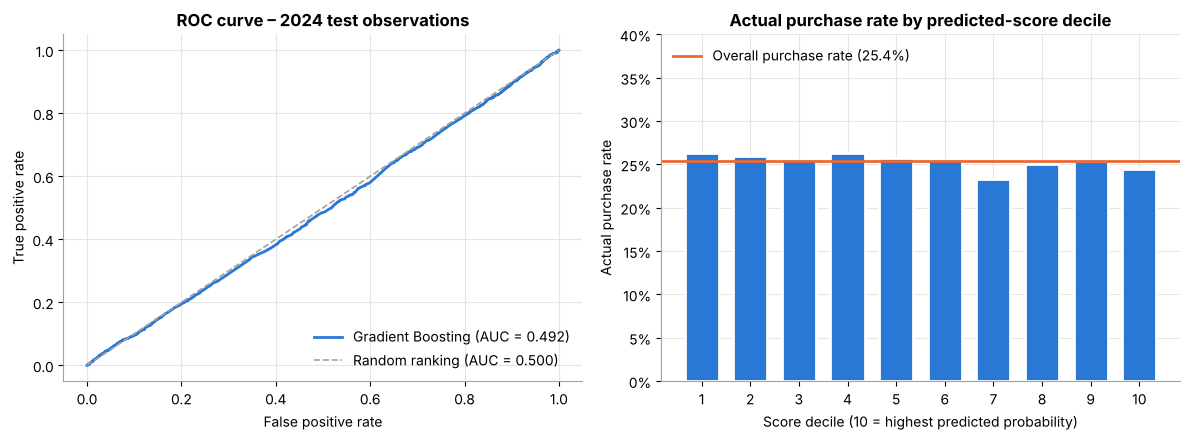

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# Chart styling, reused by every chart in the rest of the notebook
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#a3a29c",
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ROC curve
fpr, tpr, _ = roc_curve(y_class_test, test_scores)
axes[0].plot(fpr, tpr, color=COLORS[0],
             label=f"{best_classifier_name} (AUC = {roc_auc_score(y_class_test, test_scores):.3f})")
axes[0].plot([0, 1], [0, 1], color="#a3a29c", linestyle="--", linewidth=1.2,
             label="Random ranking (AUC = 0.500)")
axes[0].set(title="ROC curve – 2024 test observations",
            xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(frameon=False, loc="lower right")

# Purchase rate by predicted-score decile
deciles = pd.qcut(pd.Series(test_scores).rank(method="first"), 10, labels=range(1, 11))
decile_rates = pd.Series(y_class_test.to_numpy()).groupby(deciles.to_numpy()).mean()
axes[1].bar(decile_rates.index.astype(int), decile_rates.values, color=COLORS[0],
            width=0.7, edgecolor="white", linewidth=2)
axes[1].axhline(y_class_test.mean(), color=COLORS[1], linewidth=2,
                label=f"Overall purchase rate ({y_class_test.mean():.1%})")
axes[1].set(title="Actual purchase rate by predicted-score decile",
            xlabel="Score decile (10 = highest predicted probability)",
            ylabel="Actual purchase rate", ylim=(0, 0.4))
axes[1].set_xticks(range(1, 11))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

**Findings: classification**

- The ROC curve follows the diagonal, and the actual purchase rate is flat (≈ 25%) across all ten score deciles. Customers the model ranks highest are **no more likely** to purchase than those it ranks lowest.
- The recency rule's slight validation edge disappears on the test set (AUC ≈ 0.50, lift ≈ 1.06). Even the most intuitive retail heuristic carries no reliable information in this dataset.
- The F1-optimal model "works" only by predicting that most customers will purchase. That gives high recall at base-rate precision, which a marketer could achieve without a model by contacting everyone.

The three algorithms agree and the simple heuristic agrees too, so the cause is unlikely to be the algorithm. The diagnostics section tests this directly. First, the regression task.

# Regression: How Much Will the Customer Spend in the Next 90 Days?

## Baselines and candidate models

Because spending is zero-inflated, the choice of baseline matters:

| Baseline | Prediction | Optimal for |
|---|---|---|
| Zero / median | EGP 0 for everyone | MAE (the median minimises absolute error) |
| Training mean | Mean training spending for everyone | RMSE (the mean minimises squared error) |

A useful model must beat **both**: the zero baseline on MAE and the mean baseline on RMSE.

We compare Ridge Regression, Random Forest and Gradient Boosting, all trained to minimise squared error.

In [20]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

regressors = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=50, n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_depth=3, learning_rate=0.05, max_iter=300,
        random_state=RANDOM_STATE
    ),
}

y_reg_valid = y_reg[valid_mask]
regression_validation = [
    regression_metrics("Zero / median baseline", y_reg_valid,
                       np.zeros(valid_mask.sum())),
    regression_metrics("Training-mean baseline", y_reg_valid,
                       np.full(valid_mask.sum(), y_reg[train_mask].mean())),
]

for name, estimator in regressors.items():
    model = Pipeline([("preprocessor", make_preprocessor()),
                      ("regressor", estimator)])
    model.fit(X[train_mask], y_reg[train_mask])
    regression_validation.append(
        regression_metrics(name, y_reg_valid, model.predict(X[valid_mask]))
    )

regression_validation = pd.DataFrame(regression_validation).set_index("model")
regression_validation.round(2)

,MAE,RMSE,R2,top_10pct_revenue_share
model,,,,
Zero / median baseline,"1,097.1300","5,057.5300",-0.0500,NaN
Training-mean baseline,"1,767.9100","4,937.2500",-0.0000,NaN
Ridge Regression,"1,774.1700","4,953.9500",-0.0100,0.0800
Random Forest,"1,816.3600","4,953.9100",-0.0100,0.1000
Gradient Boosting,"1,767.1400","4,939.9500",-0.0000,0.1100


## Final test evaluation

We refit the model with the lowest validation RMSE on training + validation data and evaluate once on the test set.

In [21]:
best_regressor_name = (
    regression_validation.loc[list(regressors), "RMSE"].idxmin()
)
print("Model selected on validation RMSE:", best_regressor_name)

final_regressor = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("regressor", regressors[best_regressor_name]),
])
final_regressor.fit(X[train_full_mask], y_reg[train_full_mask])

y_reg_test = y_reg[test_mask]
test_spending_pred = final_regressor.predict(X[test_mask])
train_full_mean = y_reg[train_full_mask].mean()

regression_test = pd.DataFrame([
    regression_metrics("Zero / median baseline", y_reg_test,
                       np.zeros(test_mask.sum())),
    regression_metrics("Training-mean baseline", y_reg_test,
                       np.full(test_mask.sum(), train_full_mean)),
    regression_metrics(best_regressor_name, y_reg_test, test_spending_pred),
]).set_index("model")

regression_test.round(2)

Model selected on validation RMSE: Gradient Boosting

,MAE,RMSE,R2,top_10pct_revenue_share
model,,,,
Zero / median baseline,"1,107.1200","5,070.5400",-0.0500,NaN
Training-mean baseline,"1,771.5000","4,948.3400",-0.0000,NaN
Gradient Boosting,"1,794.5000","4,949.2000",-0.0000,0.1200


**Findings: individual-level regression**

- The zero baseline has the lowest MAE. This is expected for a target whose median is zero, and no model beats it.
- The model's RMSE is essentially the same as the training-mean baseline, and R² ≈ 0. The model explains none of the customer-to-customer variation in future spending.
- The top 10% of predicted spenders account for roughly 10% of actual future revenue, which is exactly what random selection would deliver.

## Where the regression *does* help: aggregate revenue planning

Individual customers can't be told apart, but the **total** spending of the customer base is highly predictable. For revenue planning that is the more relevant question. We forecast each test quarter's total revenue as *eligible customers × average spending per customer-observation in the training period*.

In [22]:
aggregate_forecast = (
    modeling_data.loc[test_mask]
    .groupby("snapshot_date")
    .agg(eligible_customers=("customer_id", "size"),
         actual_revenue=("future_spending", "sum"))
)
aggregate_forecast["forecast_revenue"] = (
    aggregate_forecast["eligible_customers"] * train_full_mean
)
aggregate_forecast["model_forecast_revenue"] = (
    pd.Series(test_spending_pred, index=modeling_data.index[test_mask])
    .groupby(modeling_data.loc[test_mask, "snapshot_date"]).sum()
)
aggregate_forecast["forecast_error_pct"] = (
    aggregate_forecast["forecast_revenue"] / aggregate_forecast["actual_revenue"] - 1
)

aggregate_forecast.index = aggregate_forecast.index.date
aggregate_forecast.style.format({
    "eligible_customers": "{:,.0f}",
    "actual_revenue": "EGP {:,.0f}",
    "forecast_revenue": "EGP {:,.0f}",
    "model_forecast_revenue": "EGP {:,.0f}",
    "forecast_error_pct": "{:+.1%}",
})

,eligible_customers,actual_revenue,forecast_revenue,model_forecast_revenue,forecast_error_pct
2024-03-31,"3,000","EGP 3,207,613","EGP 3,211,107","EGP 3,271,961",+0.1%
2024-06-30,"3,000","EGP 3,354,324","EGP 3,211,107","EGP 3,304,602",-4.3%
2024-09-30,"3,000","EGP 3,402,142","EGP 3,211,107","EGP 3,324,012",-5.6%


At the portfolio level, a simple per-customer run-rate forecasts each test quarter's revenue to within about 6%. Its error comes mainly from a handful of very large Electronics orders in a given quarter. The machine-learning model produces almost identical totals, which confirms it has learned the average and nothing more.

# Diagnosing the Results: Does Purchase History Carry Predictive Signal?

Two different families of algorithms and a simple business rule all perform at chance level. Before concluding anything, we need to rule out two explanations:

1. **A pipeline bug**, for example misaligned rows, leakage in reverse, or wrong date logic.
2. **No signal in the data**: future purchasing is genuinely unrelated to past behaviour.

We test each directly.

## Purchase rate by recent activity and loyalty tier

In real retail data, recent buyers and higher loyalty tiers repurchase noticeably more often. We look for that pattern here.

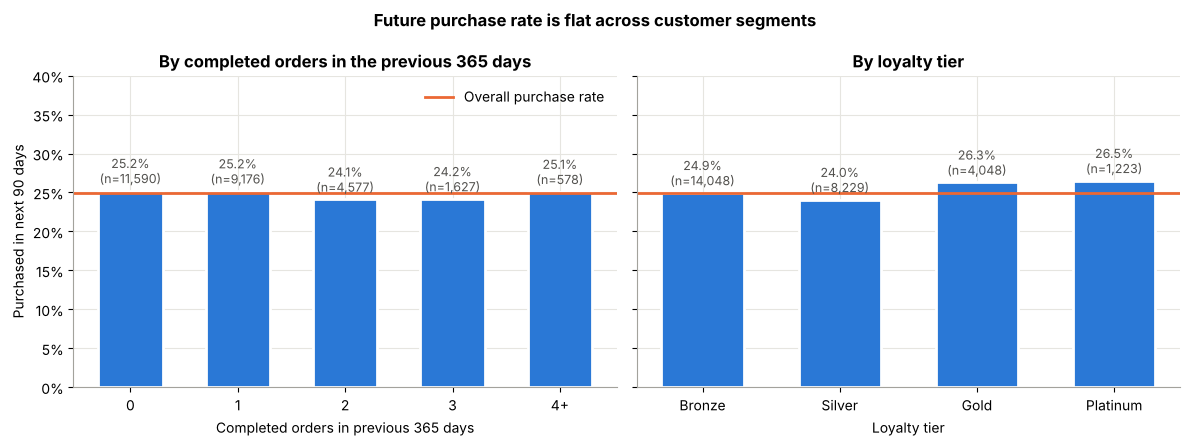

In [23]:
activity_bucket = pd.cut(
    modeling_data["orders_last_365_days"],
    bins=[-0.5, 0.5, 1.5, 2.5, 3.5, np.inf],
    labels=["0", "1", "2", "3", "4+"]
)
by_activity = (
    modeling_data.groupby(activity_bucket, observed=True)["will_purchase"]
    .agg(purchase_rate="mean", observations="size")
)
by_tier = (
    modeling_data.groupby("loyalty_tier")["will_purchase"]
    .agg(purchase_rate="mean", observations="size")
    .loc[["Bronze", "Silver", "Gold", "Platinum"]]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, table, title, xlabel in [
    (axes[0], by_activity, "By completed orders in the previous 365 days",
     "Completed orders in previous 365 days"),
    (axes[1], by_tier, "By loyalty tier", "Loyalty tier"),
]:
    ax.bar(table.index.astype(str), table["purchase_rate"], color=COLORS[0],
           width=0.6, edgecolor="white", linewidth=2)
    ax.axhline(modeling_data["will_purchase"].mean(), color=COLORS[1],
               label="Overall purchase rate")
    for i, (rate, n) in enumerate(zip(table["purchase_rate"], table["observations"])):
        ax.text(i, rate + 0.01, f"{rate:.1%}\n(n={n:,})", ha="center",
                fontsize=9, color="#52514e")
    ax.set(title=title, xlabel=xlabel, ylim=(0, 0.4))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("Purchased in next 90 days")
axes[0].legend(frameon=False, loc="upper right")
fig.suptitle("Future purchase rate is flat across customer segments",
             fontweight="bold")
plt.tight_layout()
plt.show()

The purchase rate sits at about 25% in every group. A customer with four or more orders in the past year is no more likely to buy next quarter than a customer with none, and Platinum members buy at the same rate as Bronze.

## Is purchase frequency the same for every customer?

If customers differed in how often they shop, the number of orders per customer would be **more spread out** than pure chance. For counts, a variance far above the mean (*overdispersion*) indicates real heterogeneity between customers. A variance roughly equal to the mean is what we'd expect if every customer had the **same** underlying purchase rate (a Poisson process).

In [24]:
# Completed orders per customer over the customer's registered period
registered_days = (
    pd.Timestamp("2024-12-31") - customers.set_index("customer_id")["registration_date"]
).dt.days.clip(upper=3 * 365)
order_counts = (
    completed_orders.groupby("customer_id").size()
    .reindex(customers["customer_id"]).fillna(0)
)

# Compare customers with a full three-year window, so exposure is equal
full_window = registered_days >= 3 * 365
counts = order_counts[full_window.to_numpy()]

print("Customers registered for the full 3 years:", len(counts))
print(f"Mean completed orders: {counts.mean():.2f}")
print(f"Variance:              {counts.var():.2f}")
print(f"Variance / mean ratio: {counts.var() / counts.mean():.2f}  (≈1 means no customer-level heterogeneity)")

# Correlation between a customer's activity in consecutive years
yearly = (
    completed_orders.assign(year=completed_orders["order_date"].dt.year)
    .pivot_table(index="customer_id", columns="year", values="order_id",
                 aggfunc="count", fill_value=0)
    .reindex(counts.index, fill_value=0)
)
print("\nCorrelation of order counts, 2022 vs 2023:",
      round(yearly[2022].corr(yearly[2023]), 3))
print("Correlation of order counts, 2023 vs 2024:",
      round(yearly[2023].corr(yearly[2024]), 3))

Customers registered for the full 3 years: 1479
Mean completed orders: 3.51
Variance:              3.35
Variance / mean ratio: 0.95  (≈1 means no customer-level heterogeneity)

Correlation of order counts, 2022 vs 2023: 0.007
Correlation of order counts, 2023 vs 2024: -0.036

The variance-to-mean ratio is close to 1, and a customer's order count in one year is essentially uncorrelated with the next year's. Statistically, every customer behaves like an independent draw with the **same** purchase rate. Past behaviour can't predict future behaviour because, in this dataset, there is no persistent difference between customers to learn.

## Permutation test: is the model's AUC distinguishable from chance?

We retrain the classifier many times on **shuffled** training labels, which destroys any real relationship, and compare the real model's validation AUC with that "no-signal" distribution.

In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier

rng = np.random.default_rng(RANDOM_STATE)
fast_model = lambda: Pipeline([
    ("preprocessor", make_preprocessor()),
    ("classifier", HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=150,
        random_state=RANDOM_STATE)),
])

real_auc = roc_auc_score(
    y_class[valid_mask],
    fast_model().fit(X[train_mask], y_class[train_mask])
    .predict_proba(X[valid_mask])[:, 1]
)

null_aucs = []
for _ in range(30):
    shuffled = rng.permutation(y_class[train_mask].to_numpy())
    model = fast_model().fit(X[train_mask], shuffled)
    null_aucs.append(roc_auc_score(y_class[valid_mask],
                                   model.predict_proba(X[valid_mask])[:, 1]))
null_aucs = np.array(null_aucs)

p_value = (np.sum(null_aucs >= real_auc) + 1) / (len(null_aucs) + 1)
print(f"Real-label validation AUC:      {real_auc:.4f}")
print(f"Shuffled-label AUC (mean ± sd): {null_aucs.mean():.4f} ± {null_aucs.std():.4f}")
print(f"Permutation p-value:            {p_value:.3f}")

Real-label validation AUC:      0.4955
Shuffled-label AUC (mean ± sd): 0.4992 ± 0.0103
Permutation p-value:            0.742

The model trained on real labels performs no better than models trained on shuffled labels. Its AUC falls inside the chance distribution.

## Sanity check: can the pipeline detect signal when it exists?

To rule out a bug, we create a **semi-synthetic** target with a known, realistic relationship: customers who purchased recently and frequently get a higher probability of purchasing. We then run the *same* features, split and pipeline. If the pipeline is correct, it should recover the signal.

In [26]:
# Known relationship: purchase odds rise with recent activity and fall with recency
logit = (
    -1.6
    + 0.6 * modeling_data["orders_last_365_days"]
    - 0.002 * modeling_data["recency_days"].fillna(1_000)
)
synthetic_target = pd.Series(
    rng.binomial(1, 1 / (1 + np.exp(-logit))), index=modeling_data.index
)

check_model = fast_model().fit(X[train_full_mask], synthetic_target[train_full_mask])
check_scores = check_model.predict_proba(X[test_mask])[:, 1]

print("Semi-synthetic purchase rate:", round(synthetic_target.mean(), 3))
print("Test ROC-AUC on semi-synthetic target:",
      round(roc_auc_score(synthetic_target[test_mask], check_scores), 3))
print("Top-decile lift on semi-synthetic target:",
      round(top_decile_lift(synthetic_target[test_mask], check_scores), 2))

Semi-synthetic purchase rate: 0.186
Test ROC-AUC on semi-synthetic target: 0.76
Top-decile lift on semi-synthetic target: 2.59

When a real relationship exists, the identical pipeline reaches a clearly above-chance AUC and a meaningful top-decile lift. The near-0.5 AUC on the actual target is therefore **a property of the data, not a bug** in the feature engineering, the split or the models.

## Feature importance

For completeness, we compute permutation importance for the final classifier on the test set: how much ROC-AUC drops when each feature is shuffled.

In [27]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    final_classifier, X[test_mask], y_class_test,
    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
(
    pd.DataFrame({"feature": feature_columns,
                  "mean_auc_drop": importance.importances_mean,
                  "std": importance.importances_std})
    .sort_values("mean_auc_drop", ascending=False)
    .head(10)
    .round(4)
)

,feature,mean_auc_drop,std
5,spending_last_90_days,0.0008,0.0005
0,recency_days,0.0007,0.0010
12,returned_orders,0.0003,0.0004
9,spending_last_365_days,0.0003,0.0032
11,distinct_stores,0.0001,0.0042
16,has_purchased_before,0.0000,0.0000
1,total_orders,0.0000,0.0000
6,orders_last_180_days,0.0000,0.0000
8,orders_last_365_days,0.0000,0.0000
4,orders_last_90_days,0.0000,0.0000


All importances are tiny and within their own standard deviation of zero. No feature carries reliable predictive information. Because the model has no predictive skill, we should **not** interpret any feature as a driver of repeat purchasing.

# Conclusions, Business Implications and Limitations

## Answers to the research questions

| Research question | Answer from this analysis |
|---|---|
| RQ3: Can history predict a purchase in the next 90 days? | **No.** All models and the recency rule score ROC-AUC ≈ 0.50 and top-decile lift ≈ 1.0 on 2024 data. |
| RQ4: Can history predict 90-day spending? | **Not at individual level** (R² ≈ 0; nothing beats the zero/mean baselines). **Yes at portfolio level:** a per-customer run-rate forecasts quarterly revenue to within about 6%. |
| RQ5: Which features matter most? | None reliably. Permutation importances are indistinguishable from zero. |
| RQ6: How can this support the business? | See Business implications below. |

## Business implications

1. **Revenue planning:** Quarterly revenue can be planned reliably as *active customer base × average revenue per customer*. Forecast risk comes from a few very large orders, not from customer churn, so planning should include a buffer for that volatility.
2. **Retention and marketing prioritisation:** In this data, purchase history and loyalty tier don't identify who will buy next. Ranking customers by these fields for targeted campaigns would perform no better than random selection. Broad, base-wide campaigns or randomised tests are more defensible than history-based targeting.
3. **Loyalty programme:** Higher tiers don't purchase more often. If tiers are meant to drive engagement, this is worth investigating with real data. In practice it may mean the tier benefits aren't changing behaviour.
4. **Data collection:** Useful customer-level prediction needs signals that genuinely differ between customers, for example campaign exposure and responses, website/app visits, basket contents over time, and complaint or service history.

## Limitations

- **Synthetic data.** The diagnostics show that orders behave as if assigned to customers at random, at the same rate for everyone. Real retail customers are heterogeneous. Applied to real data, this exact pipeline would be expected to find signal, as the semi-synthetic check demonstrates.
- **Pre-registration orders.** About one in six orders predates the customer's registration. These were excluded consistently, but their existence also points to independently generated fields.
- **Repeated customers across snapshots.** Observations of the same customer at consecutive dates are correlated. The chronological split protects the test evaluation, but standard errors of metrics are somewhat understated.
- **Single horizon.** Only a 90-day window was modelled. Longer horizons were outside the agreed scope.

## Key takeaway

> A model that performs at chance level is a valid and useful result when it has been tested properly. Using leakage-free features, chronological validation, multiple baselines, a permutation test and a semi-synthetic sanity check, this notebook shows that the Lotus Group data contains **no customer-level signal** for 90-day repeat purchasing or spending, while portfolio-level revenue remains highly predictable. The modelling framework is complete and ready to be reapplied to data with real customer heterogeneity.